# 02 · Bayesian analysis: adequacy of the model, convergence and sensitivity to the priors

**What this notebook does.** Notebook 01 gives the posterior of $A_{\rm raw}$. Here we ask whether it can be trusted,
using only the saved posterior sample (no new fit of the data, except the dispersed-start chain):

1. **Does the model describe the data?** Posterior predictive checks (PPC), with the statistics that the fit adjusts
   (binned $\chi^2$) and with statistics that it does not (asymmetry in mass slices, $\chi^2(B^+)-\chi^2(B^-)$).
2. **Has the chain converged?** Trace plot of 32 walkers started over the whole prior box; an independent
   Metropolis–Hastings sampler written for this analysis, against `emcee`.
3. **How much do the conclusions depend on the priors?** Bayes factor against the prior width, Savage–Dickey for the
   background shapes, reweighting of the chain to other priors, evidence by direct integration.
4. **Are the summaries meaningful?** Equal-tailed against highest-posterior-density (HPD) intervals, conditional
   against marginal posterior of $A$, sequential update of the two magnet polarities.
5. **Is the local Dalitz structure the same in the two polarities and not driven by $\phi(1020)$?**
6. **Comparison with the frequentist analysis**: profile likelihood against posterior, regions in $(A,A_b)$, and the
   uncertainty of the twelve parameters by three methods (inputs: results of the frequentist notebooks).

The model and the sampler are in `bayes_model.py`. Inputs: `results/nominal/` written by notebook 01 and
`results/external/` (copies of three result files of the frequentist analysis).

### What goes into the report

| Section | Report (appendix, *Bayesian analysis* unless stated) | Figure |
|---|---|---|
| 1 | Model adequacy: goodness of fit and posterior predictive check | `bayes_nominal_ppc` |
| 2 | Sampling and convergence diagnostics; trace plots; Metropolis–Hastings sampler | `bayes_nominal_trace` |
| 3 | Priors and Bayes factors; flat priors and the evidence; Savage–Dickey densities | `validation_bf_prior_width` |
| 4 | PPC with statistics not fitted; equal-tailed and HPD intervals; posterior of the raw asymmetry | `validation_ppc_unfitted` |
| 5 | *Local asymmetry in the Dalitz plane*: $\phi(1020)$ band and significant bins | `dalitz_phi_band` |
| 6 | *Comparison of the two approaches*; *Frequentist analysis → three methods* | `validation_profile_polarity`, `validation_region_Ab`, `uncertainties_12` |

### How to run
Same environment as notebook 01. With the saved results the notebook takes a few minutes; recomputing from scratch
takes about 25 min (the own Metropolis–Hastings sampler, 120 000 steps, is the longest block, ~11 min). Every block
checks whether its result file exists and loads it instead of recomputing; to recompute one block delete its key
from `results/nominal/validation.json` or `extras.json`.

## 0 · Setup and inputs

In [1]:
import os, sys, json, time
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm
from scipy.integrate import quad
import emcee

sys.path.insert(0, ".")
sys.path.insert(0, "..")
import bayes_model as bn
import plot_style as ps
ps.use(); C = ps.COLORS

DATA_DIR    = "../../opendata-project/Data"
RESULTS_DIR = os.path.join(os.getcwd(), "results", "nominal")
EXT_DIR     = os.path.join(os.getcwd(), "results", "external")      # results of the frequentist analysis (read only)
FIG_DIR     = os.path.join(os.getcwd(), "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name)); plt.show(); print("[saved]", os.path.join("figures", name))

def load_or_empty(name):
    p = os.path.join(RESULTS_DIR, name)
    return json.load(open(p)) if os.path.exists(p) else {}

def dump(obj, name):
    with open(os.path.join(RESULTS_DIR, name), "w") as f:
        json.dump(obj, f, indent=1)
    print("[saved]", os.path.join("results", "nominal", name))

# nominal model, data and posterior sample (written by notebook 01)
cfg     = bn.NOMINAL
cands   = bn.load_candidates(DATA_DIR)
data    = bn.select(cands, cfg)
m_obs, q_obs = data.m.to_numpy(), data.q.to_numpy()
summary = json.load(open(os.path.join(RESULTS_DIR, "nominal_summary.json")))
nom     = summary["nominal"]
names   = nom["names"]
th      = np.load(os.path.join(RESULTS_DIR, "nominal_posterior_thinned.npy"))      # (20000, 12) thinned posterior
ia, ib  = names.index("A"), names.index("A_b")
MU, SIG = nom["mu"]["median"], nom["sigma"]["median"]
post    = bn.Posterior(m_obs, q_obs, cfg)
print(f"{len(m_obs)} candidates, posterior sample {th.shape}, A = {nom['A']['median']:.4f} +- {nom['A']['sd']:.4f}")

19731 candidates, posterior sample (20000, 12), A = -0.0443 +- 0.0085


## 1 · Posterior predictive check

For a set of parameters $\theta$ drawn from the posterior a replica $y^{\rm rep}$ of the whole dataset is generated
from the model, and a discrepancy $T(y,\theta)$ is computed on the data and on the replica. The Bayesian
$p$-value is $p_B=P\big(T(y^{\rm rep},\theta)\ge T(y,\theta)\big)$. Discrepancies: the binned $\chi^2$ (10 MeV
bins, both charges and separately) and the counting asymmetry in the whole window, in the signal window
($|m-\mu|<2\sigma$) and in the sidebands ($|m-\mu|>4\sigma$). The model is flexible enough that the asymmetry
statistics are reproduced, while the $\chi^2$ is not: the model is not a perfect description of the shape of the
spectrum (the mass shape is the nuisance part; its effect on $A$ is quantified by the systematic study in notebook 01).

**Figure `bayes_nominal_ppc`.** Distribution of the discrepancy in the replicas (histogram) against the observed value.

[resume] results/nominal/ppc.json
chi2             T_obs =  174.6950   T_rep =  103.8398 +- 14.7864   p_B = 0.000
chi2_pos         T_obs =  100.5458   T_rep =   51.8853 +- 10.3877   p_B = 0.000
chi2_neg         T_obs =   73.5755   T_rep =   51.9545 +- 10.4754   p_B = 0.030
A_window         T_obs =   -0.0432   T_rep =   -0.0432 +- 0.0098   p_B = 0.996
A_signal_window  T_obs =   -0.0461   T_rep =   -0.0465 +- 0.0110   p_B = 0.992
A_sidebands      T_obs =   -0.0106   T_rep =   -0.0182 +- 0.0246   p_B = 0.734


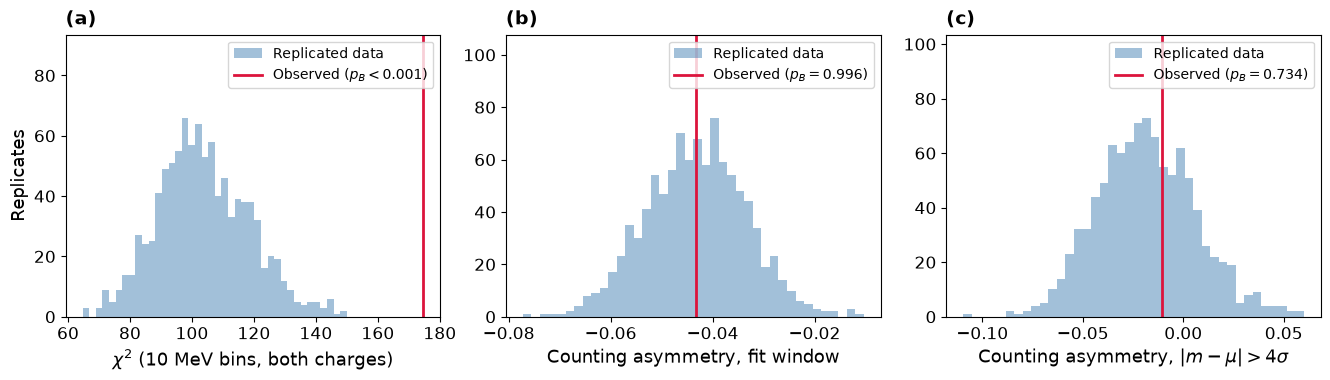

[saved] figures/bayes_nominal_ppc.pdf


In [2]:
N_REP = 1000
def count_asym(q):
    return float((np.sum(q < 0) - np.sum(q > 0)) / len(q)) if len(q) else float("nan")

def discrepancies(m, q, theta):
    sw, sb = np.abs(m - MU) < 2 * SIG, np.abs(m - MU) > 4 * SIG
    g = bn.binned_gof(bn.Posterior(m, q, cfg), theta)
    return {"chi2": g["chi2"], "chi2_pos": g["per_charge"]["pos"], "chi2_neg": g["per_charge"]["neg"],
            "A_window": count_asym(q), "A_signal_window": count_asym(q[sw]), "A_sidebands": count_asym(q[sb])}

path = os.path.join(RESULTS_DIR, "ppc.json")
if os.path.exists(path):
    ppc = json.load(open(path)); print("[resume]", os.path.relpath(path))
else:
    rng = np.random.default_rng(2026)
    rows = []
    for i in rng.choice(len(th), N_REP, replace=False):
        m_rep, q_rep = bn.generate_toy(dict(zip(names, th[i])), cfg, rng)
        rows.append({"obs": discrepancies(m_obs, q_obs, th[i]), "rep": discrepancies(m_rep, q_rep, th[i])})
    ppc = {"n_rep": N_REP, "rows": rows, "p_B": {}}
    for key in rows[0]["obs"]:
        o = np.array([r["obs"][key] for r in rows]); r_ = np.array([r["rep"][key] for r in rows])
        ppc["p_B"][key] = float(np.mean(r_ >= o)) if key.startswith("chi2") else float(2 * min(np.mean(r_ >= o), np.mean(r_ <= o)))
    dump(ppc, "ppc.json")
for key, p in ppc["p_B"].items():
    o = np.array([r["obs"][key] for r in ppc["rows"]]); r_ = np.array([r["rep"][key] for r in ppc["rows"]])
    print(f"{key:16s} T_obs = {np.median(o):9.4f}   T_rep = {r_.mean():9.4f} +- {r_.std():.4f}   p_B = {p:.3f}")

fig, axs = plt.subplots(1, 3, figsize=(ps.TRIPLE, 4.0))
for k_, (a, key, lab) in enumerate(((axs[0], "chi2", r"$\chi^2$ (10 MeV bins, both charges)"),
                                    (axs[1], "A_window", r"Counting asymmetry, fit window"),
                                    (axs[2], "A_sidebands", r"Counting asymmetry, $|m-\mu|>4\sigma$"))):
    ps.letter(a, "abc"[k_])
    o = np.array([r["obs"][key] for r in ppc["rows"]]); r_ = np.array([r["rep"][key] for r in ppc["rows"]])
    a.hist(r_, bins=40, histtype="stepfilled", color=C["replica"], alpha=0.5, label="Replicated data")
    pB = ppc["p_B"][key]
    a.axvline(np.median(o), color=C["observed"], lw=2, label=f"Observed ($p_B={pB:.3g}$)" if pB >= 0.01 else "Observed ($p_B<0.001$)")
    a.set_xlabel(lab); a.set_ylim(0, a.get_ylim()[1] * 1.35); a.legend(loc="upper right", fontsize=10)
axs[0].set_ylabel("Replicates")
plt.tight_layout()
save_fig(fig, "bayes_nominal_ppc.pdf")

## 2 · Convergence of the chain

### 2.1 Chain started far from the posterior (trace plot)

The nominal chains of notebook 01 start in a ball around the maximum of the posterior. To exclude that the result
depends on the starting point, 32 walkers are started uniformly over the whole prior box (25 000 steps, saved every
10): the chain must reach the same posterior. Dotted line: half of the chain, discarded as burn-in when the
posterior is computed.

**Figure `bayes_nominal_trace`.** Left: first 3 000 steps; right: the whole chain, for $A$, $N_s$, $\sigma$ and $f_+$.

[resume] results/nominal/trace_dispersed.npz
A, second half of the chain: median -0.0440354198217392  sd 0.00856824778020382


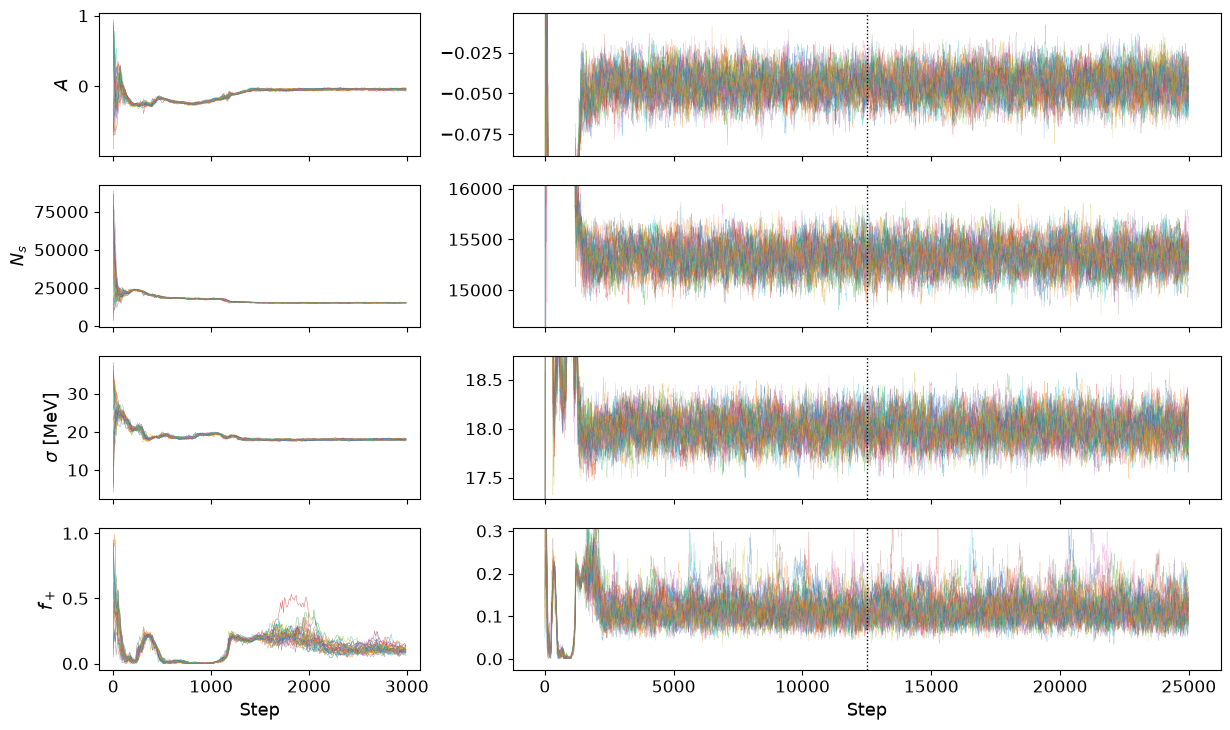

[saved] figures/bayes_nominal_trace.pdf


In [3]:
path_tr = os.path.join(RESULTS_DIR, "trace_dispersed.npz")
if os.path.exists(path_tr):
    print("[resume]", os.path.relpath(path_tr))
else:
    lo_, hi_ = bn._prior_box(cfg, post.n, names)
    rng = np.random.default_rng(7)
    pos = lo_ + (hi_ - lo_) * rng.uniform(0.02, 0.98, (32, len(names)))
    for w in range(32):                       # same rule as bn.fit: every walker starts inside the prior
        while not np.isfinite(post(pos[w])):
            pos[w] = lo_ + (hi_ - lo_) * rng.uniform(0.02, 0.98, len(names))
    np.random.seed(7)
    sam = emcee.EnsembleSampler(32, len(names), post)
    sam.run_mcmc(pos, 25000, progress=False)
    ch_ = sam.get_chain()[::10].astype(np.float32)          # (2500, 32, 12)
    np.savez_compressed(path_tr, chain=ch_, names=np.array(names), thin=10, lnp=sam.get_log_prob()[::10].astype(np.float32))
    print("[saved]", os.path.relpath(path_tr), ch_.shape)
tr = np.load(path_tr)
ch, tnames, thin = tr["chain"], list(tr["names"]), int(tr["thin"])
half = ch.shape[0] // 2
print("A, second half of the chain: median", float(np.median(ch[half:, :, tnames.index("A")])),
      " sd", float(np.std(ch[half:, :, tnames.index("A")])))

show = [("A", r"$A$"), ("N_s", r"$N_s$"), ("sigma", r"$\sigma$ [MeV]"), ("f_pos", r"$f_+$")]
steps = np.arange(ch.shape[0]) * thin
n_early = 3000 // thin
fig, axs = plt.subplots(len(show), 2, figsize=(ps.DOUBLE, 7.5), sharex="col", gridspec_kw={"width_ratios": [1, 2.2]})
for row, (k, lab) in enumerate(show):
    y = ch[:, :, tnames.index(k)]
    axs[row, 0].plot(steps[:n_early], y[:n_early], lw=0.4, alpha=0.6)
    axs[row, 1].plot(steps, y, lw=0.3, alpha=0.4)
    lo_q, hi_q = np.percentile(y[half:], [0.5, 99.5]); pad = 0.5 * (hi_q - lo_q)
    axs[row, 1].set_ylim(lo_q - pad, hi_q + pad)
    axs[row, 1].axvline(ch.shape[0] * thin // 2, color="k", ls=":", lw=1)
    axs[row, 0].set_ylabel(lab)
axs[-1, 0].set_xlabel("Step"); axs[-1, 1].set_xlabel("Step")
plt.tight_layout()
save_fig(fig, "bayes_nominal_trace.pdf")

### 2.2 Independent sampler: Metropolis–Hastings against `emcee`

A random-walk Metropolis–Hastings sampler written for this analysis, with a Gaussian proposal whose covariance is
that of the `emcee` posterior scaled by $2.38^2/d$ (optimal for Gaussian targets), sampling the same log-posterior.
Agreement of the two samplers on the median and width of $A$ checks the implementation of the sampling, not only
the posterior itself. 120 000 steps, first sixth discarded (about 11 min).

In [4]:
EXT_PATH = "extras.json"
ext = load_or_empty(EXT_PATH)

def metropolis(logp, x0, cov, n_steps, rng):
    d = len(x0); L = np.linalg.cholesky(cov * 2.38 ** 2 / d)
    x = x0.copy(); lp = logp(x); chain = np.empty((n_steps, d)); acc = 0
    for i in range(n_steps):
        y = x + L @ rng.standard_normal(d)
        lq = logp(y)
        if np.log(rng.random()) < lq - lp:
            x, lp = y, lq; acc += 1
        chain[i] = x
    return chain, acc / n_steps

mp = np.array([nom["map"][n] for n in names])            # maximum of the posterior (start of the chain)
if "metropolis_hastings" not in ext:
    rng = np.random.default_rng(11); t0 = time.time(); n_steps = 120000
    chain, acc = metropolis(post, mp.copy(), np.cov(th.T), n_steps, rng)
    burn = n_steps // 6; chm = chain[burn:]
    try:
        tau = emcee.autocorr.integrated_time(chm[:, ia], quiet=True)[0]
    except Exception:
        tau = float("nan")
    ext["metropolis_hastings"] = dict(
        n_steps=n_steps, burn=burn, acceptance=float(acc), seconds=time.time() - t0,
        A_median=float(np.median(chm[:, ia])), A_sd=float(chm[:, ia].std()),
        A_ci68=[float(np.percentile(chm[:, ia], 15.865)), float(np.percentile(chm[:, ia], 84.135))],
        tau_A=float(tau), n_eff=float(len(chm) / tau),
        emcee=dict(A_median=nom["A"]["median"], A_sd=nom["A"]["sd"], A_ci68=nom["A"]["ci68"]),
        note="Gaussian proposal with the covariance of the emcee posterior scaled by 2.38^2/d")
    dump(ext, EXT_PATH)
mh = ext["metropolis_hastings"]
print(f"Metropolis-Hastings: acceptance {mh['acceptance']:.2f}, tau_A = {mh['tau_A']:.0f}, effective sample {mh['n_eff']:.0f}")
print(f"  A = {mh['A_median']:.4f} +- {mh['A_sd']:.4f}   68% CI [{mh['A_ci68'][0]:.4f}, {mh['A_ci68'][1]:.4f}]")
print(f"  emcee: A = {mh['emcee']['A_median']:.4f} +- {mh['emcee']['A_sd']:.4f}   68% CI "
      f"[{mh['emcee']['A_ci68'][0]:.4f}, {mh['emcee']['A_ci68'][1]:.4f}]")

Metropolis-Hastings: acceptance 0.24, tau_A = 36, effective sample 2813
  A = -0.0443 +- 0.0084   68% CI [-0.0526, -0.0357]
  emcee: A = -0.0443 +- 0.0085   68% CI [-0.0528, -0.0358]


## 3 · Sensitivity to the priors

With a large dataset the posterior of $A$ does not depend on the prior, but the Bayes factor does: it is
proportional to the prior density at $A=0$. Four checks.

### 3.1 Bayes factor against the width of the prior on $A$ and $A_b$

Uniform prior $(-W,W)$: the Savage–Dickey ratio is $\mathrm{BF}_{01}=p(0\mid{\rm data})\cdot 2W$. The question is how
wide the prior has to be to change the conclusion; the posterior density at 0 is the Gaussian approximation of
the marginal posterior, as in notebook 01.

**Figure `validation_bf_prior_width`.** $\mathrm{BF}_{01}$ against $W$ for $A$ and $A_b$ (vertical line: the
nominal prior, $W=1$).

A   : posterior density at 0 = 5.68e-05;  BF01 at W=0.1: 1.14e-05, at W=1: 1.14e-04
A_b : posterior density at 0 = 1.73;  BF01 at W=0.1: 3.45e-01, at W=1: 3.45e+00


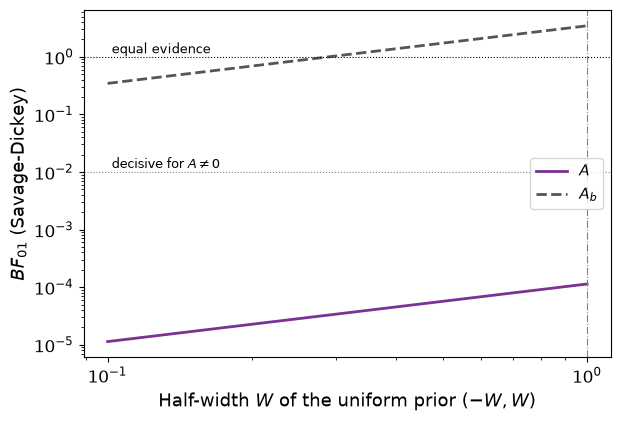

[saved] figures/validation_bf_prior_width.pdf


In [5]:
VAL_PATH = "validation.json"
val = load_or_empty(VAL_PATH)
if "bf_vs_prior_width" not in val:
    W = np.geomspace(0.1, 1.0, 19)
    val["bf_vs_prior_width"] = {"W": W.tolist()}
    for par in ("A", "A_b"):
        m_, s_ = nom[par]["mean"], nom[par]["sd"]
        p0 = norm.pdf(0.0, m_, s_)
        val["bf_vs_prior_width"][par] = dict(post_density_at_0=float(p0), bf01=(p0 * 2 * W).tolist())
    dump(val, VAL_PATH)
bfw = val["bf_vs_prior_width"]; W = np.array(bfw["W"])
for par in ("A", "A_b"):
    print(f"{par:4s}: posterior density at 0 = {bfw[par]['post_density_at_0']:.3g};  BF01 at W=0.1: {bfw[par]['bf01'][0]:.2e}, at W=1: {bfw[par]['bf01'][-1]:.2e}")

fig, ax = plt.subplots(figsize=(ps.SINGLE, 4.4))
ax.plot(W, bfw["A"]["bf01"], color=C["bayes"], lw=2, label=r"$A$")
ax.plot(W, bfw["A_b"]["bf01"], color=C["count"], lw=2, ls="--", label=r"$A_b$")
ax.axhline(1, color="k", ls=":", lw=0.8); ax.axhline(1e-2, color="gray", ls=":", lw=0.8)
ax.text(W[0] * 1.02, 1.15, "equal evidence", fontsize=9); ax.text(W[0] * 1.02, 1.15e-2, "decisive for $A\\neq0$", fontsize=9)
ax.axvline(1.0, color=C["background"], lw=0.8, ls="-.")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"Half-width $W$ of the uniform prior $(-W,W)$"); ax.set_ylabel(r"$BF_{01}$ (Savage-Dickey)")
ax.legend(loc="center right")
plt.tight_layout()
save_fig(fig, "validation_bf_prior_width.pdf")

### 3.2 Savage–Dickey for the equality of the background shapes of $B^+$ and $B^-$

The background shape is separate for the two charges. Is that necessary? For each pair of parameters
($\lambda_1,\lambda_2,f$) the difference $\Delta=\theta_+-\theta_-$ is tested against $\Delta=0$ with Savage–Dickey: the
posterior density of $\Delta$ at 0 over the prior density of the difference of two independent uniform
variables at 0 (for $\lambda_2$, with the constraint $\lambda_2<\lambda_1$, the prior density is computed by
numerical integration).

In [6]:
if "savage_dickey_background_shapes" not in val:
    eps, lam_max = 1e-5, 0.1
    def prior_diff_density_at_0(kind):
        if kind == "lam1":
            return 1.0 / (lam_max - eps)
        if kind == "f":
            return 1.0
        # lam2 ~ U(eps, lam1), lam1 ~ U(eps, lam_max): marginal prior of lam2, density of the difference at 0
        p = lambda x: np.log((lam_max - eps) / (x - eps)) / (lam_max - eps)
        return quad(lambda x: p(x) ** 2, eps * (1 + 1e-9), lam_max, limit=200)[0]
    sd_res = {}
    for kind, a, b in (("lam1", "lam1_pos", "lam1_neg"), ("lam2", "lam2_pos", "lam2_neg"), ("f", "f_pos", "f_neg")):
        dlt = th[:, names.index(a)] - th[:, names.index(b)]
        m_, s_ = float(dlt.mean()), float(dlt.std())
        p0 = float(norm.pdf(0.0, m_, s_)); pr = float(prior_diff_density_at_0(kind))
        sd_res[kind] = dict(mean=m_, sd=s_, z=m_ / s_, post_density_at_0=p0, prior_density_at_0=pr, bf01=p0 / pr)
    val["savage_dickey_background_shapes"] = sd_res
    dump(val, VAL_PATH)
for kind, r in val["savage_dickey_background_shapes"].items():
    print(f"{kind:5s} Delta = {r['mean']:+.4g} +- {r['sd']:.3g} ({r['z']:+.1f} sd)   BF01 = {r['bf01']:.2f}")

lam1  Delta = +0.007493 +- 0.00911 (+0.8 sd)   BF01 = 3.12
lam2  Delta = +0.001154 +- 0.000475 (+2.4 sd)   BF01 = 2.21
f     Delta = -0.09432 +- 0.0468 (-2.0 sd)   BF01 = 1.12


### 3.3 Other priors by importance reweighting of the chain

The posterior sample is reweighted by $\pi'(\theta)/\pi(\theta)$ to obtain the posterior under another prior,
without new MCMC. Priors: log-uniform in the yields (Jeffreys-like), log-uniform and lifetime-uniform in the slopes,
and flat in $(N_s^+,N_s^-)$ [and $(N_b^+,N_b^-)$] instead of $(N,A)$ (the Jacobian of the change of variables is
$N_s$ [$N_b$]). The effective sample size $1/\sum w^2$ tells how reliable each reweighting is.

In [7]:
def wq(x, w, q):                                  # weighted quantile
    o = np.argsort(x); c = np.cumsum(w[o]) / w.sum()
    return float(x[o][np.searchsorted(c, q)])

A_s, Ab_s = th[:, ia], th[:, ib]
if "prior_reweighting" not in ext:
    col = lambda k: th[:, names.index(k)]
    lam = np.vstack([col(k) for k in ("lam1_pos", "lam2_pos", "lam1_neg", "lam2_neg")])
    variants = {
        "nominal": np.ones(len(th)),
        "log-uniform N_s, N_b": 1.0 / (col("N_s") * col("N_b")),
        "log-uniform slopes": 1.0 / lam.prod(axis=0),
        "uniform lifetimes 1/lambda": lam.prod(axis=0) ** -2.0,
        "flat in (N_s^+, N_s^-)": col("N_s"),
        "flat in (N_s^+, N_s^-) and (N_b^+, N_b^-)": col("N_s") * col("N_b"),
    }
    pr = {}
    for k, w in variants.items():
        w = w / w.sum()
        pr[k] = dict(median=wq(A_s, w, 0.5), lo=wq(A_s, w, 0.1587), hi=wq(A_s, w, 0.8413), ess=float(1.0 / np.sum(w ** 2)))
    ext["prior_reweighting"] = pr
    dump(ext, EXT_PATH)
print(f"{'prior':44s} {'median A':>9s}  {'68% interval':>20s}   ESS")
for k, v in ext["prior_reweighting"].items():
    print(f"{k:44s} {v['median']:+9.4f}  [{v['lo']:+.4f}, {v['hi']:+.4f}]  {v['ess']:7.0f}")

prior                                         median A          68% interval   ESS
nominal                                        -0.0442  [-0.0529, -0.0358]    20000
log-uniform N_s, N_b                           -0.0442  [-0.0529, -0.0358]    19993
log-uniform slopes                             -0.0440  [-0.0528, -0.0356]    12306
uniform lifetimes 1/lambda                     -0.0444  [-0.0526, -0.0360]      153
flat in (N_s^+, N_s^-)                         -0.0442  [-0.0529, -0.0358]    19999
flat in (N_s^+, N_s^-) and (N_b^+, N_b^-)      -0.0442  [-0.0529, -0.0358]    19993


### 3.4 Evidence by direct integration

The marginal likelihood of $\mathcal M_1$ over $A$ with the nuisance parameters **fixed at the MAP** (grid integration
in $A$, the course method), and with the profile likelihood of the frequentist analysis (parabola fitted to
$q(A)$, `results/external/profiles.json`), against the Savage–Dickey value of notebook 01 (marginalised over the
nuisance parameters). The three are Bayes factors of the same hypotheses with different treatments of the
nuisance parameters; they must agree in order of magnitude and conclusion.

In [8]:
if "evidence" not in ext:
    grid = np.linspace(-0.2, 0.2, 801)
    ll = []
    for a in grid:
        t = mp.copy(); t[ia] = a; ll.append(post(t))
    ll = np.array(ll); L = np.exp(ll - ll.max())
    Z1 = np.trapezoid(L * 0.5, grid)                       # prior density 1/2 on (-1,1); the likelihood vanishes outside the grid
    L0 = np.exp(post(np.where(np.arange(len(mp)) == ia, 0.0, mp)) - ll.max())
    ev = dict(K01_grid_nuisance_fixed_at_MAP=float(L0 / Z1))
    pf = json.load(open(os.path.join(EXT_DIR, "profiles.json")))["profile"]["all"]
    a_, q_ = np.array(pf["A"]), np.array(pf["q"])
    c = np.polyfit(a_[q_ < 9], q_[q_ < 9], 2)
    fine = np.linspace(-0.2, 0.2, 4001)
    Lp = np.exp(-0.5 * (np.polyval(c, fine) - np.polyval(c, -c[1] / (2 * c[0]))))
    Zp = np.trapezoid(Lp * 0.5, fine)
    L0p = np.exp(-0.5 * (np.polyval(c, 0.0) - np.polyval(c, -c[1] / (2 * c[0]))))
    ev["K01_profile_likelihood"] = float(L0p / Zp)
    ev["savage_dickey_marginal"] = summary["bayes_factor"]["A0_BF01"]
    ext["evidence"] = ev
    dump(ext, EXT_PATH)
for k, v in ext["evidence"].items():
    print(f"{k:42s} BF_01 = {v:.2e}")

K01_grid_nuisance_fixed_at_MAP             BF_01 = 7.01e-05
K01_profile_likelihood                     BF_01 = 1.29e-04
savage_dickey_marginal                     BF_01 = 1.14e-04


## 4 · Further posterior predictive check and summaries of the posterior

### 4.1 Statistics that the fit does not adjust

The binned $\chi^2$ is optimised (indirectly) by the fit, so it is a weak test. Two statistics that are not:

* $T=\sum_{s=1}^{10}(A_s-\bar A_s)^2/\sigma_s^2$, the asymmetry in ten 50 MeV mass slices against the one predicted by
  the model (the signal and background asymmetries are constants of the model, the slice asymmetry varies only
  through the signal fraction);
* $D=\chi^2(B^+)-\chi^2(B^-)$, difference of the goodness of fit of the two charges (from section 1).

**Figure `validation_ppc_unfitted`.** (a) data and model in the slices; (b),(c) $T$ and $D$ in the replicas against
the observed value.

T (10 slices): observed 7.1, replicas 10.0 +- 4.4, p_B = 0.666
D = chi2(B+) - chi2(B-): observed 27.0, replicas -0.1 +- 14.7, p_B (two-sided) = 0.076


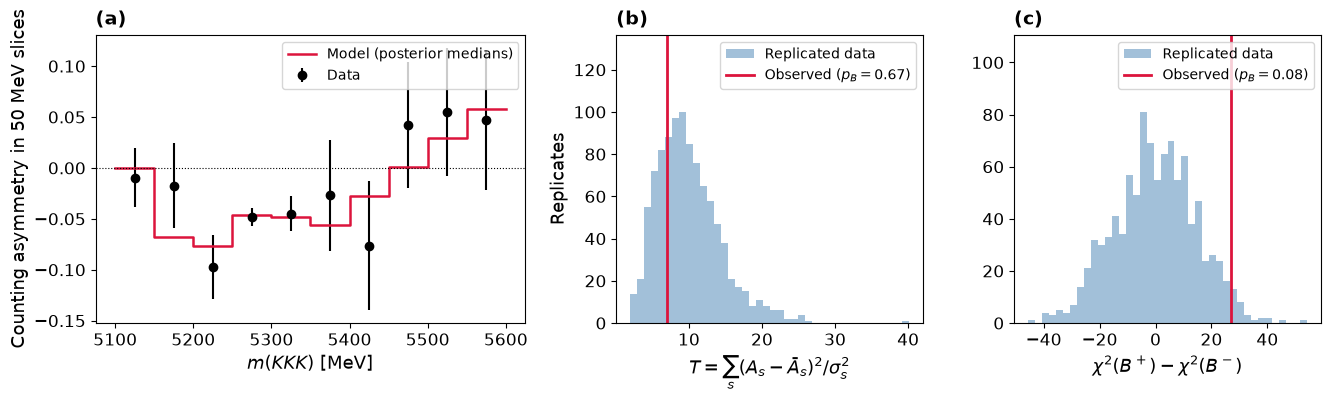

[saved] figures/validation_ppc_unfitted.pdf


In [9]:
if "ppc_unfitted" not in val:
    edges = np.linspace(cfg.lo, cfg.hi, 11)
    grid = np.linspace(cfg.lo, cfg.hi, 5001)
    idx_slice = np.digitize(grid, edges[1:-1])
    def expected(theta_dict):
        d = post.unpack(np.array([theta_dict[n] for n in names]))
        sig = bn._signal_pdf(grid, d, cfg)
        ep = d["N_s"] * (1 - d["A"]) / 2 * sig + d["N_b"] * (1 - d["A_b"]) / 2 * bn._bkg_pdf(grid, d, "pos", cfg)
        en = d["N_s"] * (1 + d["A"]) / 2 * sig + d["N_b"] * (1 + d["A_b"]) / 2 * bn._bkg_pdf(grid, d, "neg", cfg)
        Ep = np.array([np.trapezoid(ep[idx_slice == k], grid[idx_slice == k]) for k in range(10)])
        En = np.array([np.trapezoid(en[idx_slice == k], grid[idx_slice == k]) for k in range(10)])
        return Ep, En
    def T_slices(m, q, Ep, En):
        a_exp = (En - Ep) / (En + Ep); var = (1 - a_exp ** 2) / (En + Ep)
        npos, _ = np.histogram(m[q > 0], edges); nneg, _ = np.histogram(m[q < 0], edges)
        a_obs = (nneg - npos) / np.maximum(nneg + npos, 1)
        return float(np.sum((a_obs - a_exp) ** 2 / var))

    rng = np.random.default_rng(2026); n_rep = 1000
    To, Tr = [], []
    for i in rng.choice(len(th), n_rep, replace=False):
        td = dict(zip(names, th[i])); Ep, En = expected(td)
        m_r, q_r = bn.generate_toy(td, cfg, rng)
        To.append(T_slices(m_obs, q_obs, Ep, En)); Tr.append(T_slices(m_r, q_r, Ep, En))
    To, Tr = np.array(To), np.array(Tr)
    Do = np.array([r["obs"]["chi2_pos"] - r["obs"]["chi2_neg"] for r in ppc["rows"]])
    Dr = np.array([r["rep"]["chi2_pos"] - r["rep"]["chi2_neg"] for r in ppc["rows"]])
    val["ppc_unfitted"] = dict(
        n_rep=n_rep, slices_edges=edges.tolist(),
        T_slices=dict(obs_median=float(np.median(To)), rep_mean=float(Tr.mean()), rep_sd=float(Tr.std()), p_B=float(np.mean(Tr >= To)),
                      obs=To.tolist(), rep=Tr.tolist(), ndof=10),
        D_chi2=dict(obs_median=float(np.median(Do)), rep_mean=float(Dr.mean()), rep_sd=float(Dr.std()),
                    p_B_two_sided=float(2 * min(np.mean(Dr >= Do), np.mean(Dr <= Do))), obs=Do.tolist(), rep=Dr.tolist()))
    # data and model (posterior medians) slice by slice, for panel (a)
    Ep, En = expected(dict(zip(names, np.median(th, axis=0))))
    npos, _ = np.histogram(m_obs[q_obs > 0], edges); nneg, _ = np.histogram(m_obs[q_obs < 0], edges)
    a_o = (nneg - npos) / (nneg + npos)
    val["slices"] = dict(centers=(0.5 * (edges[1:] + edges[:-1])).tolist(), A_obs=a_o.tolist(),
                         A_err=np.sqrt((1 - a_o ** 2) / (nneg + npos)).tolist(), A_model=((En - Ep) / (En + Ep)).tolist())
    dump(val, VAL_PATH)

pp, sl = val["ppc_unfitted"], val["slices"]
print(f"T (10 slices): observed {pp['T_slices']['obs_median']:.1f}, replicas {pp['T_slices']['rep_mean']:.1f} +- {pp['T_slices']['rep_sd']:.1f}, p_B = {pp['T_slices']['p_B']:.3f}")
print(f"D = chi2(B+) - chi2(B-): observed {pp['D_chi2']['obs_median']:.1f}, replicas {pp['D_chi2']['rep_mean']:.1f} +- {pp['D_chi2']['rep_sd']:.1f}, "
      f"p_B (two-sided) = {pp['D_chi2']['p_B_two_sided']:.3f}")

fig, axs = plt.subplots(1, 3, figsize=(ps.TRIPLE, 4.2), gridspec_kw={"width_ratios": [1.4, 1, 1]})
a = axs[0]; ps.letter(a, "a")
x = np.array(sl["centers"])
a.errorbar(x, sl["A_obs"], yerr=sl["A_err"], fmt="o", color=C["data"], label="Data")
a.step(np.append(x - 25, x[-1] + 25), np.append(sl["A_model"], sl["A_model"][-1]), where="post", color=C["model"], lw=1.8,
       label="Model (posterior medians)")
a.axhline(0, color="k", ls=":", lw=0.8)
a.set_xlabel(r"$m(KKK)$ [MeV]"); a.set_ylabel("Counting asymmetry in 50 MeV slices"); a.legend(loc="upper right", fontsize=10)
for k, (key, lab) in enumerate((("T_slices", r"$T=\sum_s(A_s-\bar A_s)^2/\sigma_s^2$"), ("D_chi2", r"$\chi^2(B^+)-\chi^2(B^-)$")), 1):
    a = axs[k]; ps.letter(a, "bc"[k - 1])
    o, r_ = np.array(pp[key]["obs"]), np.array(pp[key]["rep"])
    a.hist(r_, bins=40, color=C["replica"], alpha=0.5, label="Replicated data")
    a.axvline(np.median(o), color=C["observed"], lw=2, label=f"Observed ($p_B={pp[key].get('p_B', pp[key].get('p_B_two_sided')):.2f}$)")
    a.set_xlabel(lab); a.set_ylim(0, a.get_ylim()[1] * 1.3); a.legend(loc="upper right", fontsize=10)
axs[1].set_ylabel("Replicates")
plt.tight_layout()
save_fig(fig, "validation_ppc_unfitted.pdf")

### 4.2 Sequential update with the two magnet polarities

Bayesian learning is sequential: the posterior of the magnet-down sample is the prior of the magnet-up sample.
Multiplying the two posteriors of $A$ (kernel density estimates of the chains of notebook 01) and normalising gives
the posterior of the sequential analysis, which must coincide with the joint fit of all the data if the two samples
share the same $A$ and the same nuisance parameters are not too different.

In [10]:
if "sequential_update" not in val:
    from scipy.stats import gaussian_kde
    d_ = np.load(os.path.join(RESULTS_DIR, "magnet_down_A_thinned.npy")); u_ = np.load(os.path.join(RESULTS_DIR, "magnet_up_A_thinned.npy"))
    xs = np.linspace(-0.14, 0.05, 4000)
    post_seq = gaussian_kde(d_)(xs) * gaussian_kde(u_)(xs); post_seq /= np.trapezoid(post_seq, xs)
    cdf = np.cumsum(post_seq) * (xs[1] - xs[0])
    mean = float(np.trapezoid(xs * post_seq, xs)); sd = float(np.sqrt(np.trapezoid((xs - mean) ** 2 * post_seq, xs)))
    val["sequential_update"] = dict(
        down=dict(median=float(np.median(d_)), sd=float(d_.std())), up=dict(median=float(np.median(u_)), sd=float(u_.std())),
        updated=dict(mean=mean, sd=sd, median=float(xs[np.searchsorted(cdf, 0.5)]),
                     ci68=[float(xs[np.searchsorted(cdf, 0.1587)]), float(xs[np.searchsorted(cdf, 0.8413)])]),
        joint_fit=dict(median=nom["A"]["median"], sd=nom["A"]["sd"], ci68=nom["A"]["ci68"]))
    dump(val, VAL_PATH)
s = val["sequential_update"]
print(f"down : {s['down']['median']:+.4f} +- {s['down']['sd']:.4f}")
print(f"up   : {s['up']['median']:+.4f} +- {s['up']['sd']:.4f}")
print(f"down x up (sequential): {s['updated']['median']:+.4f} +- {s['updated']['sd']:.4f}  68% [{s['updated']['ci68'][0]:+.4f}, {s['updated']['ci68'][1]:+.4f}]")
print(f"joint fit             : {s['joint_fit']['median']:+.4f} +- {s['joint_fit']['sd']:.4f}  68% [{s['joint_fit']['ci68'][0]:+.4f}, {s['joint_fit']['ci68'][1]:+.4f}]")

down : -0.0498 +- 0.0112
up   : -0.0378 +- 0.0129
down x up (sequential): -0.0446 +- 0.0086  68% [-0.0533, -0.0359]
joint fit             : -0.0443 +- 0.0085  68% [-0.0528, -0.0358]


### 4.3 Conditional against marginal posterior of $A$; equal-tailed against HPD intervals

* $A$ and $A_b$ are correlated in the posterior. The report quotes the **marginal** posterior of $A$; the symmetric
  background model ($A_b=0$ fixed) corresponds to the posterior **conditional** on $A_b=0$. For a Gaussian posterior
  the conditional mean is $\bar A+\rho\,\frac{\sigma_A}{\sigma_{A_b}}(0-\bar A_b)$ and the width is reduced by
  $\sqrt{1-\rho^2}$. The prediction is compared with the chain restricted to $|A_b|<0.004$ and with the fit of the
  symmetric-background variant of notebook 01.
* The 68 % **equal-tailed** interval (16th–84th percentile) against the **highest posterior density** interval (the
  shortest interval containing 68 %) for all twelve parameters; the skewness tells when they differ.

In [11]:
if "conditional" not in ext:
    cov = np.cov(A_s, Ab_s)
    near = np.abs(Ab_s) < 0.004
    ext["conditional"] = dict(
        marginal_mean=float(A_s.mean()), corr=float(cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])), sd_A=float(A_s.std()), sd_Ab=float(Ab_s.std()),
        A_b_mean=float(Ab_s.mean()), predicted_A_given_Ab0=float(A_s.mean() + cov[0, 1] / cov[1, 1] * (0.0 - Ab_s.mean())),
        predicted_sd=float(np.sqrt(cov[0, 0] - cov[0, 1] ** 2 / cov[1, 1])),
        chain_A_given_Ab_near0=dict(n=int(near.sum()), median=float(np.median(A_s[near])), sd=float(A_s[near].std())),
        symmetric_background_fit_bayes=summary["variations"]["bkg_symmetric"]["A"]["median"],
        symmetric_background_fit_sd=summary["variations"]["bkg_symmetric"]["A"]["sd"])
    dump(ext, EXT_PATH)
cd = ext["conditional"]
print(f"marginal  A = {cd['marginal_mean']:+.4f} +- {cd['sd_A']:.4f};  corr(A, A_b) = {cd['corr']:+.2f}")
print(f"Gaussian prediction given A_b = 0 : {cd['predicted_A_given_Ab0']:+.4f} +- {cd['predicted_sd']:.4f}")
print(f"chain with |A_b| < 0.004          : {cd['chain_A_given_Ab_near0']['median']:+.4f} +- {cd['chain_A_given_Ab_near0']['sd']:.4f}  (n = {cd['chain_A_given_Ab_near0']['n']})")
print(f"fit with symmetric background     : {cd['symmetric_background_fit_bayes']:+.4f} +- {cd['symmetric_background_fit_sd']:.4f}")

def hpd(x, p=0.6827):
    s = np.sort(x); n = len(s); k = int(np.ceil(p * n))
    w = s[k:] - s[:n - k]; j = int(np.argmin(w)); return float(s[j]), float(s[j + k])

if "hpd_vs_equal_tailed" not in ext:
    rows = {}
    for k, n in enumerate(names):
        x = th[:, k]; q16, q84 = np.percentile(x, [15.865, 84.135])
        rows[n] = dict(median=float(np.median(x)), equal_tailed=[float(q16), float(q84)], hpd=list(hpd(x)), skewness=float(stats.skew(x)))
    ext["hpd_vs_equal_tailed"] = rows
    dump(ext, EXT_PATH)
print(f"\n{'parameter':10s} {'median':>10s}  {'equal-tailed 68%':>26s}  {'HPD 68%':>26s}  skew")
for n, r in ext["hpd_vs_equal_tailed"].items():
    print(f"{n:10s} {r['median']:10.4g}  [{r['equal_tailed'][0]:10.4g}, {r['equal_tailed'][1]:10.4g}]  "
          f"[{r['hpd'][0]:10.4g}, {r['hpd'][1]:10.4g}]  {r['skewness']:+.2f}")

marginal  A = -0.0443 +- 0.0085;  corr(A, A_b) = -0.17
Gaussian prediction given A_b = 0 : -0.0475 +- 0.0084
chain with |A_b| < 0.004          : -0.0472 +- 0.0078  (n = 301)
fit with symmetric background     : -0.0471 +- 0.0083

parameter      median            equal-tailed 68%                     HPD 68%  skew
N_s         1.533e+04  [ 1.519e+04,  1.546e+04]  [  1.52e+04,  1.546e+04]  +0.00
N_b              4403  [      4321,       4486]  [      4321,       4486]  +0.03
A             -0.0442  [  -0.05285,    -0.0358]  [  -0.05249,   -0.03548]  +0.01
A_b          -0.03999  [  -0.05746,   -0.02243]  [  -0.05752,   -0.02254]  +0.01
mu               5284  [      5284,       5285]  [      5284,       5285]  -0.02
sigma              18  [     17.87,      18.14]  [     17.86,      18.14]  +0.07
lam1_pos      0.03504  [   0.02808,    0.04314]  [   0.02745,    0.04233]  +0.52
lam2_pos     0.002798  [  0.002499,   0.003071]  [  0.002539,   0.003105]  -0.42
f_pos          0.1136  [   0.08864,    

## 5 · Dalitz structure by magnet polarity and resonances

Two questions on the local asymmetry found in notebook 01:

1. **Magnet polarity.** The left–right part of the detection asymmetry flips sign when the magnet polarity is
   inverted, while a $CP$-violating asymmetry does not. The $8\times8$ maps of the asymmetry of magnet down and
   magnet up are compared: homogeneity test in each, correlation of the two maps and $\chi^2$ of the bin-by-bin
   difference. The region defined by the two bins with $|S|>3$ of the full sample is quoted in each polarity.
2. **Resonances.** The $\phi(1020)$ band ($|m_{\rm lo}-m_\phi|<10$ MeV) is symmetric: the asymmetry of the region is
   not driven by $\phi(1020)$.

In [12]:
from scipy.stats import chi2 as chi2_dist
def local_map(lo2, hi2, q, nx=8, ny=8):
    el, eh = np.linspace(0, 16, nx + 1), np.linspace(0, 30, ny + 1)
    npl, _, _ = np.histogram2d(lo2[q > 0], hi2[q > 0], [el, eh]); nmi, _, _ = np.histogram2d(lo2[q < 0], hi2[q < 0], [el, eh])
    n = npl + nmi; ag = (np.sum(q < 0) - np.sum(q > 0)) / len(q)
    with np.errstate(divide="ignore", invalid="ignore"):
        a = (nmi - npl) / n; s = (a - ag) / np.sqrt((1 - a ** 2) / n)
    return n, a, s, ag

lo2 = (np.minimum(data.m12, data.m13).to_numpy() / 1e3) ** 2
hi2 = (np.maximum(data.m12, data.m13).to_numpy() / 1e3) ** 2
mag = data.magnet.to_numpy()
out, maps = {}, {}
for pol in ("all", "down", "up"):
    sel = np.ones(len(q_obs), bool) if pol == "all" else (mag == pol)
    n, a, s, ag = local_map(lo2[sel], hi2[sel], q_obs[sel])
    ok = n >= 20
    c2 = float(np.nansum(s[ok] ** 2)); nd = int(ok.sum() - 1)
    reg = (lo2[sel] < 4) & (hi2[sel] > 7.5) & (hi2[sel] < 11.25)       # the two |S|>3 bins of the full sample
    qr = q_obs[sel][reg]; ar = (np.sum(qr < 0) - np.sum(qr > 0)) / len(qr); sr = np.sqrt((1 - ar ** 2) / len(qr))
    out[pol] = {"n": int(sel.sum()), "A_glob": float(ag), "chi2": c2, "ndof": nd, "p": float(chi2_dist.sf(c2, nd)),
                "n_3sigma": int(np.sum(np.abs(s[ok]) > 3)),
                "region": {"n": int(len(qr)), "A": float(ar), "sigma": float(sr), "S_vs_global": float((ar - ag) / sr)}}
    maps[pol] = (n, a, s)
both = (maps["down"][0] >= 20) & (maps["up"][0] >= 20)
r = np.corrcoef(maps["down"][1][both], maps["up"][1][both])[0, 1]
nd_, ad_ = maps["down"][0][both], maps["down"][1][both]; nu_, au_ = maps["up"][0][both], maps["up"][1][both]
dz = (ad_ - au_) / np.sqrt((1 - ad_ ** 2) / nd_ + (1 - au_ ** 2) / nu_)
c2d, ndd = float(np.sum(dz ** 2)), int(both.sum())
out["down_vs_up"] = {"n_bins": ndd, "pearson_A": float(r), "chi2_difference": c2d, "ndof": ndd, "p": float(chi2_dist.sf(c2d, ndd))}
dump(out, "dalitz_magnet.json")
for k, v in out.items():
    print(k, json.dumps(v))

[saved] results/nominal/dalitz_magnet.json
all {"n": 19731, "A_glob": -0.04323146317976788, "chi2": 80.77695659889034, "ndof": 31, "p": 2.57145541911995e-06, "n_3sigma": 2, "region": {"n": 3091, "A": -0.12779035910708508, "sigma": 0.017839189862752396, "S_vs_global": -4.740063678781357}}
down {"n": 11636, "A_glob": -0.05139223100721898, "chi2": 60.72194559717751, "ndof": 31, "p": 0.0011087680451687342, "n_3sigma": 0, "region": {"n": 1839, "A": -0.12887438825448613, "sigma": 0.02312449922508832, "S_vs_global": -3.3506523316710317}}
up {"n": 8095, "A_glob": -0.03150092649783817, "chi2": 39.52971152958374, "ndof": 28, "p": 0.0727714123519915, "n_3sigma": 1, "region": {"n": 1252, "A": -0.12619808306709265, "sigma": 0.0280357206515586, "S_vs_global": -3.377732206216356}}
down_vs_up {"n_bins": 29, "pearson_A": 0.5044509114158304, "chi2_difference": 22.961535893152366, "ndof": 29, "p": 0.7783005194458201}


**Resonances and figure `dalitz_phi_band`.** Counting asymmetry (not a fit) in the $\phi(1020)$ band, in the
low-mass region outside it, in the two significant bins and in the significant bins with and without $\phi$. These
numbers are the *a posteriori* description of a region that was selected because it is significant: they are an
illustration, not a new significance.

[saved] results/nominal/dalitz_resonances.json
phi_band                         n=  1964  A_count = -0.0041 +- 0.0226
phi_sideband_lo2_below_2         n=  4833  A_count = -0.1198 +- 0.0143
significant_bins                 n=  3091  A_count = -0.1278 +- 0.0178
significant_bins_without_phi     n=  2738  A_count = -0.1446 +- 0.0189
significant_bins_phi_only        n=   353  A_count = +0.0028 +- 0.0532
global                           n= 19731  A_count = -0.0432 +- 0.0071


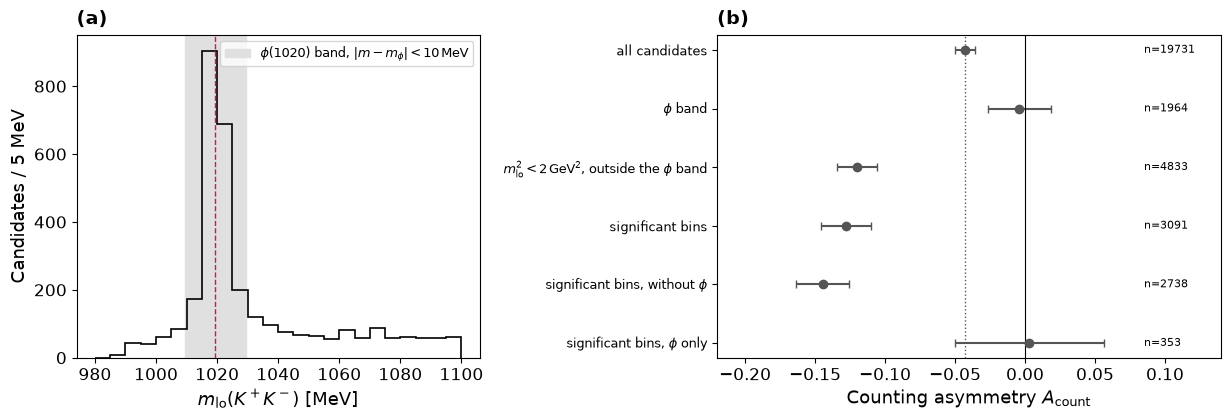

[saved] figures/dalitz_phi_band.pdf


In [13]:
m_lo = np.minimum(data.m12, data.m13).to_numpy(); m_hi = np.maximum(data.m12, data.m13).to_numpy()
def cnt(sel):
    qq = q_obs[sel]; a = (np.sum(qq < 0) - np.sum(qq > 0)) / len(qq)
    return {"n": int(len(qq)), "A": float(a), "sigma": float(np.sqrt((1 - a ** 2) / len(qq)))}
PHI = 1019.461   # MeV, world average
phi = np.abs(m_lo - PHI) < 10
reg_sig = ((m_lo / 1e3) ** 2 < 4) & ((m_hi / 1e3) ** 2 > 7.5) & ((m_hi / 1e3) ** 2 < 11.25)   # the two |S|>3 bins
res = {"phi_band": cnt(phi), "phi_sideband_lo2_below_2": cnt(~phi & ((m_lo / 1e3) ** 2 < 2.0)),
       "significant_bins": cnt(reg_sig), "significant_bins_without_phi": cnt(reg_sig & ~phi),
       "significant_bins_phi_only": cnt(reg_sig & phi), "global": cnt(np.ones(len(q_obs), bool))}
h, e = np.histogram(m_lo, np.arange(980, 1100.1, 5))
res["m_lo_hist_980_1100_5MeV"] = h.tolist()
dump(res, "dalitz_resonances.json")
for k, v in res.items():
    if k != "m_lo_hist_980_1100_5MeV":
        print(f"{k:32s} n={v['n']:6d}  A_count = {v['A']:+.4f} +- {v['sigma']:.4f}")

edges = np.arange(980, 1100.1, 5)
fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
a = axs[0]; ps.letter(a, "a")
a.stairs(h, edges, color="k", lw=1.2)
a.axvspan(PHI - 10, PHI + 10, color="0.88", zorder=0, label=r"$\phi(1020)$ band, $|m-m_\phi|<10\,$MeV")
a.axvline(PHI, color=C["observed"], ls="--", lw=1)
a.set_xlabel(r"$m_{\mathrm{lo}}(K^+K^-)$ [MeV]"); a.set_ylabel("Candidates / 5 MeV"); a.legend(fontsize=9, loc="upper right")
b = axs[1]; ps.letter(b, "b")
rows = [("all candidates", "global"), (r"$\phi$ band", "phi_band"),
        (r"$m^2_{\mathrm{lo}}<2\,\mathrm{GeV}^2$, outside the $\phi$ band", "phi_sideband_lo2_below_2"),
        ("significant bins", "significant_bins"), (r"significant bins, without $\phi$", "significant_bins_without_phi"),
        (r"significant bins, $\phi$ only", "significant_bins_phi_only")]
y = np.arange(len(rows))[::-1]
for yy, (lab, key) in zip(y, rows):
    v = res[key]
    b.errorbar(v["A"], yy, xerr=v["sigma"], fmt="o", color=C["count"], capsize=3)
    b.text(0.085, yy, "n=%d" % v["n"], va="center", fontsize=8)
b.axvline(res["global"]["A"], color=C["count"], ls=":", lw=1); b.axvline(0, color="k", lw=0.8)
b.set_yticks(y); b.set_yticklabels([l for l, _ in rows], fontsize=9)
b.set_xlim(-0.22, 0.14); b.set_xlabel(r"Counting asymmetry $A_{\mathrm{count}}$")
plt.tight_layout()
save_fig(fig, "dalitz_phi_band.pdf")

## 6 · Comparison with the frequentist analysis

The inputs are result files of the frequentist notebooks, copied unchanged to `results/external/`:
`profiles.json` (profile likelihood $q(A)=-2\Delta\ln L$ of the joint fit and of the two polarities, and the
confidence regions in $(A,A_b)$) and `cov_summary.json` (uncertainty of the twelve parameters by Hesse, bootstrap
and MCMC). No frequentist code is run here.

**Figure `validation_profile_polarity`.** (a) The marginal posterior of $A$ and the likelihood $e^{-q(A)/2}$
(normalised) are almost identical: with flat priors and a large sample the two inferences coincide numerically but
mean different things. (b) The profile $q(A)$ of the two polarities; their sum is the frequentist analogue of the
sequential update of section 4.2.

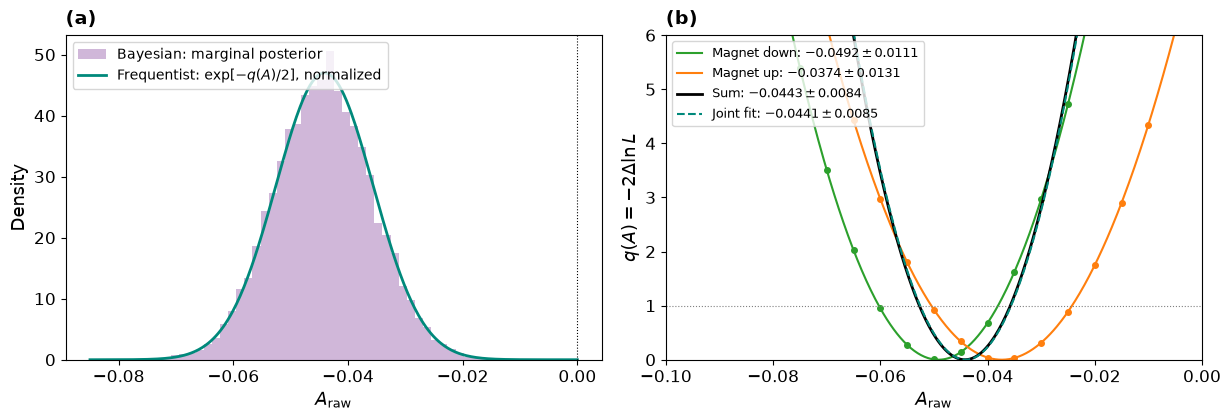

[saved] figures/validation_profile_polarity.pdf


In [14]:
from scipy.ndimage import gaussian_filter
from matplotlib.lines import Line2D
prof = json.load(open(os.path.join(EXT_DIR, "profiles.json")))
A_post, Ab_post = th[:, ia], th[:, ib]

def parabola(a, q, qmax=9.0):
    # quadratic fit q(A) = q0 + (A - a0)^2 / s^2 on the points with q < qmax: returns a0, s and the function q(A) - q0
    a, q = np.asarray(a), np.asarray(q); k = q < qmax
    c = np.polyfit(a[k], q[k], 2)
    a0 = -c[1] / (2 * c[0]); s = 1 / np.sqrt(c[0]); q0 = np.polyval(c, a0)
    return a0, s, (lambda x: np.polyval(c, x) - q0)

fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 4.4))
a = axs[0]; ps.letter(a, "a")
pa = prof["profile"]["all"]
a0, s0, f = parabola(pa["A"], pa["q"])
xs = np.linspace(-0.085, 0.0, 400)
like = np.exp(-0.5 * f(xs)); like /= np.trapezoid(like, xs)
a.hist(A_post, bins=60, range=(xs[0], xs[-1]), density=True, color=C["bayes"], alpha=0.35, label="Bayesian: marginal posterior")
a.plot(xs, like, color=C["freq"], lw=2, label=r"Frequentist: $\exp[-q(A)/2]$, normalized")
a.axvline(0, color="k", ls=":", lw=0.8)
a.set_xlabel(r"$A_{\mathrm{raw}}$"); a.set_ylabel("Density"); a.legend(loc="upper left", fontsize=10)
a = axs[1]; ps.letter(a, "b")
col = {"down": C["down"], "up": C["up"]}
qs = 0
for w in ("down", "up"):
    p_ = prof["profile"][w]
    a0_, s_, f_ = parabola(p_["A"], p_["q"])
    a.plot(p_["A"], p_["q"], "o", color=col[w], ms=4)
    a.plot(xs, f_(xs), color=col[w], lw=1.5, label=f"Magnet {w}: ${a0_:+.4f}\\pm{s_:.4f}$")
    qs = qs + f_(xs)
j = np.argmin(qs); a_c = xs[j]
inside = xs[qs <= qs[j] + 1]
a.plot(xs, qs - qs[j], color="k", lw=2, label=f"Sum: ${a_c:+.4f}\\pm{0.5*(inside.max()-inside.min()):.4f}$")
a.plot(xs, f(xs), color=C["freq"], lw=1.5, ls="--", label=f"Joint fit: ${a0:+.4f}\\pm{s0:.4f}$")
a.axhline(1, color="gray", ls=":", lw=0.8)
a.set_ylim(0, 6); a.set_xlim(-0.1, 0.0)
a.set_xlabel(r"$A_{\mathrm{raw}}$"); a.set_ylabel(r"$q(A)=-2\Delta\ln L$"); a.legend(loc="upper left", fontsize=9)
plt.tight_layout()
save_fig(fig, "validation_profile_polarity.pdf")

**Figure `validation_region_Ab`.** Joint region of $(A,A_b)$: the frequentist contours (profile likelihood, $\chi^2_2$
thresholds) and the Bayesian highest-posterior-density regions containing 68 % and 95 % of the posterior.

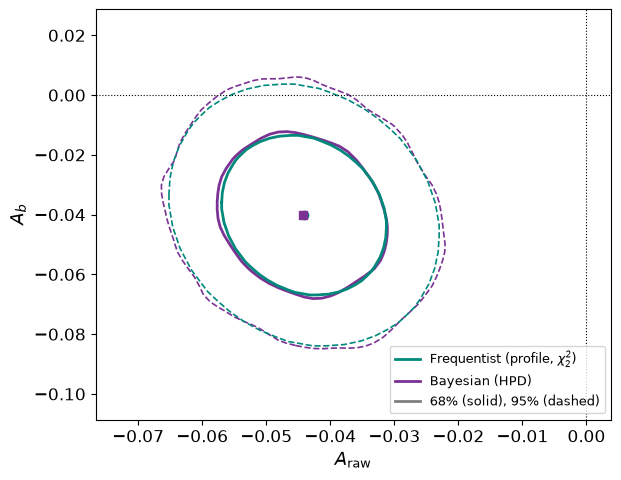

[saved] figures/validation_region_Ab.pdf


In [15]:
ab = prof["A_Ab"]
fig, ax = plt.subplots(figsize=(ps.SINGLE, 5.0))
H, xe, ye = np.histogram2d(A_post, Ab_post, bins=50, density=True)
H = gaussian_filter(H, 1.5)
Hs = np.sort(H.ravel())[::-1]; cum = np.cumsum(Hs) * (xe[1] - xe[0]) * (ye[1] - ye[0])
lev = [Hs[np.searchsorted(cum, p)] for p in (0.6827, 0.9545)]
xc, yc = 0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1])
ax.contour(xc, yc, H.T, levels=sorted(lev), colors=[C["bayes"]], linewidths=[1.2, 2.0], linestyles=["--", "-"])
for tag, ls_, lw in (("c95", "--", 1.2), ("c68", "-", 2.0)):
    pts = np.array(ab[tag]); pts = np.vstack([pts, pts[:1]])
    ax.plot(pts[:, 0], pts[:, 1], color=C["freq"], ls=ls_, lw=lw)
ax.plot([ab["A"]], [ab["A_b"]], "o", color=C["freq"], ms=6)
ax.plot([np.median(A_post)], [np.median(Ab_post)], "s", color=C["bayes"], ms=6)
ax.axhline(0, color="k", ls=":", lw=0.8); ax.axvline(0, color="k", ls=":", lw=0.8)
ax.legend(handles=[Line2D([], [], color=C["freq"], lw=2, label="Frequentist (profile, $\\chi^2_2$)"),
                   Line2D([], [], color=C["bayes"], lw=2, label="Bayesian (HPD)"),
                   Line2D([], [], color="gray", lw=2, label="68% (solid), 95% (dashed)")], loc="lower right", fontsize=9)
ax.set_xlabel(r"$A_{\mathrm{raw}}$"); ax.set_ylabel(r"$A_b$")
plt.tight_layout()
save_fig(fig, "validation_region_Ab.pdf")

**Figure `uncertainties_12`.** Uncertainty of each of the twelve parameters by three methods, as a ratio to the
Hesse (asymptotic, from the curvature of the likelihood) uncertainty: bootstrap of the data (frequentist, 300
replicas) and standard deviation of the posterior (MCMC). Within the grey band ($\pm10\,\%$) the three methods agree.

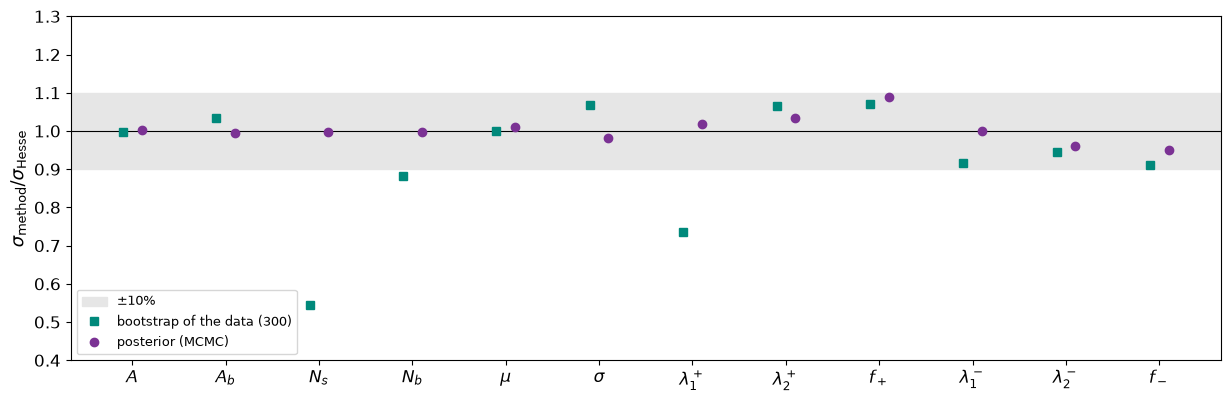

[saved] figures/uncertainties_12.pdf


In [16]:
cv = json.load(open(os.path.join(EXT_DIR, "cov_summary.json")))["sigma"]
order = [("A", r"$A$"), ("A_b", r"$A_b$"), ("N_s", r"$N_s$"), ("N_b", r"$N_b$"), ("mu", r"$\mu$"), ("sigma", r"$\sigma$"),
         ("lam1_pos", r"$\lambda_1^+$"), ("lam2_pos", r"$\lambda_2^+$"), ("f_pos", r"$f_+$"),
         ("lam1_neg", r"$\lambda_1^-$"), ("lam2_neg", r"$\lambda_2^-$"), ("f_neg", r"$f_-$")]
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(ps.DOUBLE, 4.2))
ax.axhspan(0.9, 1.1, color="0.9", label=r"$\pm10\%$")
ax.axhline(1, color="k", lw=0.8)
ax.plot(x - 0.1, [cv[k]["bootstrap"] / cv[k]["hesse"] for k, _ in order], "s", color=C["freq"], label="bootstrap of the data (300)")
ax.plot(x + 0.1, [cv[k]["mcmc"] / cv[k]["hesse"] for k, _ in order], "o", color=C["bayes"], label="posterior (MCMC)")
ax.set_xticks(x); ax.set_xticklabels([l for _, l in order])
ax.set_ylabel(r"$\sigma_{\mathrm{method}}/\sigma_{\mathrm{Hesse}}$"); ax.set_ylim(0.4, 1.3)
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout()
save_fig(fig, "uncertainties_12.pdf")